[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Tnecniv-Teikram/NSA-hyperspectral-course-2026/blob/main/exercises/solutions/ex_03_ghg_plumes_solutions.ipynb)

*Running in Colab? Run the setup cell below first — it clones the course and installs what this notebook needs. Running locally? It does nothing.*

# 💨 Solutions: Air quality & GHG plumes
### Space Academy 2026 · Hyperspectral course · Week 2 — Project scoping and use case definition (Practical)

Stress-test the simple methane band ratio (MBSI) from notebook 03 over the Kusmunda coal mine in India — one of Asia's largest open-cast mines — and find out what it really measures. This is a lesson in scientific scepticism: always ask what else could cause the signal.

These exercises accompany the theme notebook [`03_air_quality_ghg_plumes.ipynb`](../https://github.com/Tnecniv-Teikram/813-hyperspectral-hackathon/blob/main/03_air_quality_ghg_plumes.ipynb). Run that notebook first
(or at least read it) — here we reuse its scene and indices, loaded with the course helper module `hsi_utils`.

> 🧑‍🏫 **Instructor version** — worked solutions with outputs. Students get the version without solutions in `exercises/`.

**What you will practise**
- Locating index 'hot spots' and judging whether they are plausible
- Testing the sensitivity of an index to arbitrary choices (reference bands)
- Diagnosing surface-driven false positives with land-cover labels and spectra
- Using the GHG-plumes STAC metadata and provider plume products as reference data
- What a defensible gas-detection workflow needs

**Data**
- `20250219_053251_31_4001` — Kusmunda / Korba coalfield, Chhattisgarh, India (19 Feb 2025)
- `data/labels/…_worldcover2021_30m.tif` — ESA WorldCover 2021 on the Tanager grid
- Exercise 5 needs internet (Planet STAC catalogue).

In [ ]:
# --- Setup: works both in Google Colab and in a local environment --------------------
# In Colab this clones the course repository, installs the geospatial packages that Colab
# does not ship, and moves into the course folder so the notebook finds hsi_utils and data/.
# Locally it does nothing at all — your own environment is already active.
import os
import pathlib
import subprocess
import sys

REPO = "Tnecniv-Teikram/NSA-hyperspectral-course-2026"          # change with: python tools/set_repo_url.py <owner>/<repo>

if "google.colab" in sys.modules:
    course = pathlib.Path("/content/hyperspectral-course")
    if not course.exists():
        subprocess.run(["git", "clone", "--depth", "1", "-q",
                        f"https://github.com/{REPO}.git", str(course)], check=True)
    os.chdir(course)
    sys.path.insert(0, str(course))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "h5py", "rasterio", "rioxarray", "xarray", "geopandas"], check=True)
    print("Colab ready — course at", course)
else:
    print("Local environment:", sys.executable.split("/")[-3])


## Setup

In [1]:
# hsi_utils.py lives in the course folder (../.. from here)
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parents[1]))

# On Google Colab: upload hsi_utils.py next to this notebook, change the line above to
# sys.path.insert(0, ".") and uncomment:
# %pip install -q h5py numpy scipy matplotlib scikit-learn pandas rasterio requests

import numpy as np
import matplotlib.pyplot as plt
import hsi_utils as hu

plt.rcParams["figure.dpi"] = 90

Load the scene and the bands used in the theme notebook. `hu.get_scene()` finds the local HDF5 or downloads it (~1 GB) from Planet's STAC catalogue.

Scene      : 20250219_053251_31_4001  (Korba, Chhattisgarh, India)
File       : /home/course/notebooks/20250219_053251_31_4001_ortho_sr_hdf5.h5
Cube       : 426 bands × 961 rows × 811 cols
Wavelengths: 376–2499 nm, FWHM 5.2–6.8 nm
Good bands : 352 of 426
Grid       : EPSG:32644, 30 m pixels
No-data    : 27.6%   cloud flag: 0.0%   cirrus flag: 0.0%   usable: 72.4%


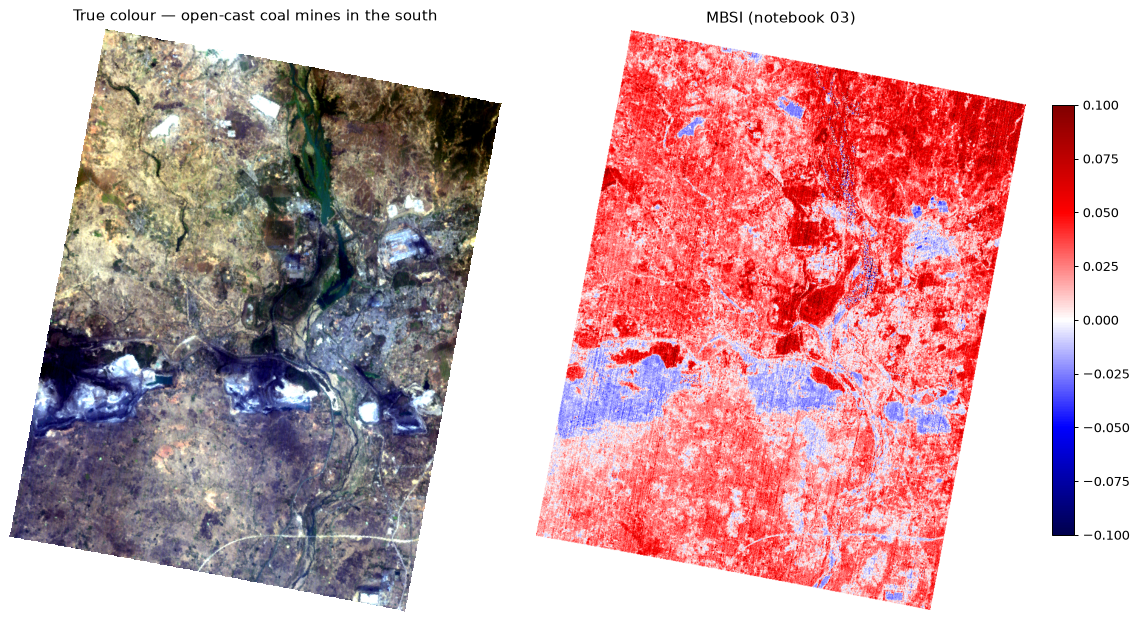

In [2]:
SCENE_ID = "20250219_053251_31_4001"   # Kusmunda coal mine, Korba, Chhattisgarh, India (GHG-plumes)
scene = hu.get_scene(SCENE_ID)
print(scene.summary())

valid = scene.valid_mask()
R = {w: scene.read_band(w) for w in (2150, 2200, 2250, 2305, 2345, 2380, 2420, 480, 560, 665, 860, 1650)}

def mbsi(ref1=2250, ref2=2380, abs1=2305, abs2=2345):
    """Methane Band Suppression Index of notebook 03: shoulders / absorption − 1."""
    r_abs = (R[abs1] + R[abs2]) / 2
    return (R[ref1] + R[ref2]) / (2 * r_abs + 1e-6) - 1

MBSI = mbsi()
NDVI = hu.nd(R[860], R[665])
ALBEDO = np.mean([R[w] for w in (480, 560, 665, 860, 1650)], axis=0)
wc, purity = hu.load_labels(SCENE_ID)
ok = valid & np.isfinite(MBSI)

fig, axes = plt.subplots(1, 2, figsize=(13, 7))
axes[0].imshow(scene.rgb()); axes[0].set_title("True colour — open-cast coal mines in the south")
im = axes[1].imshow(np.where(ok, MBSI, np.nan), cmap="seismic", vmin=-0.1, vmax=0.1)
axes[1].set_title("MBSI (notebook 03)"); plt.colorbar(im, ax=axes[1], fraction=0.04)
for a in axes: a.axis("off")
plt.tight_layout(); plt.show()

## Exercise 1 — Where are the 'methane hot spots'?  ⭐

Notebook 03 treats high MBSI as a possible methane signal.

1. Find the pixels in the top 0.5% of MBSI (valid pixels only) and overlay them in a bright colour on the
   true-colour image.
2. How many are there and what do these places look like? Are they on the mines, the power plants or somewhere
   else?

### Solution

MBSI threshold (99.5th pct) = 0.087; 2,834 hot-spot pixels


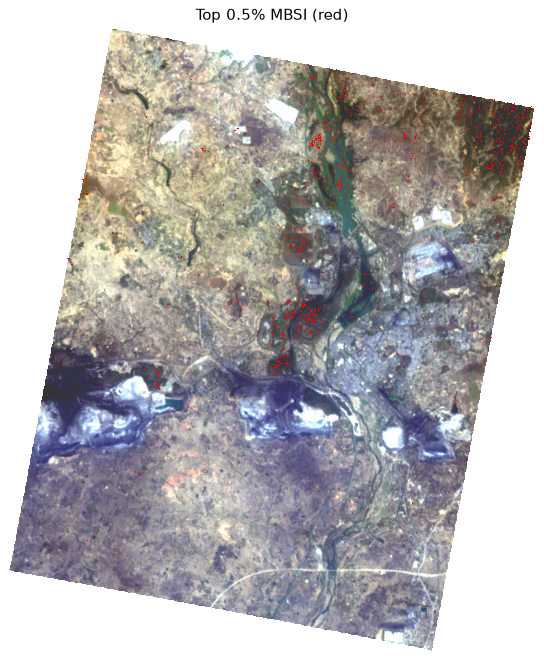

In [3]:
t = np.nanpercentile(MBSI[ok], 99.5)
hot = ok & (MBSI > t)
print(f"MBSI threshold (99.5th pct) = {t:.3f}; {hot.sum():,} hot-spot pixels")

fig, ax = plt.subplots(figsize=(8, 9))
ax.imshow(scene.rgb(), alpha=0.8)
ax.imshow(np.where(hot, 1, np.nan), cmap="autumn", interpolation="nearest")
ax.set_title("Top 0.5% MBSI (red)"); ax.axis("off")
plt.show()

**Interpretation:** the "hot spots" are *not* on the mines or the power-plant stacks. They are scattered
along the dark green riparian forests, wooded hills and the reservoir margins. The mine pits themselves are
among the *lowest* MBSI values. A real methane plume would be a coherent, wind-elongated feature starting at
a source, and nothing like that appears here. That already suggests MBSI is reacting to the *surface*.

## Exercise 2 — Sensitivity to the reference bands  ⭐⭐

MBSI compares the absorption bands (2305 and 2345 nm) with two "shoulder" reference bands (2250 and 2380 nm).
The choice of shoulders is arbitrary. Recompute MBSI with the shoulder pairs **(2200, 2420)** and
**(2150, 2420)** and compare:

1. the Pearson correlation of each version with the original, over valid pixels;
2. the overlap of the top-0.5% hot-spot sets, measured by the Jaccard index |A ∩ B| / |A ∪ B|.

Would a robust detection change this much?

### Solution

(2250, 2380) original    r = 1.00   Jaccard(top 0.5%) = 1.00
(2200, 2420)             r = 0.84   Jaccard(top 0.5%) = 0.14
(2150, 2420)             r = 0.74   Jaccard(top 0.5%) = 0.08


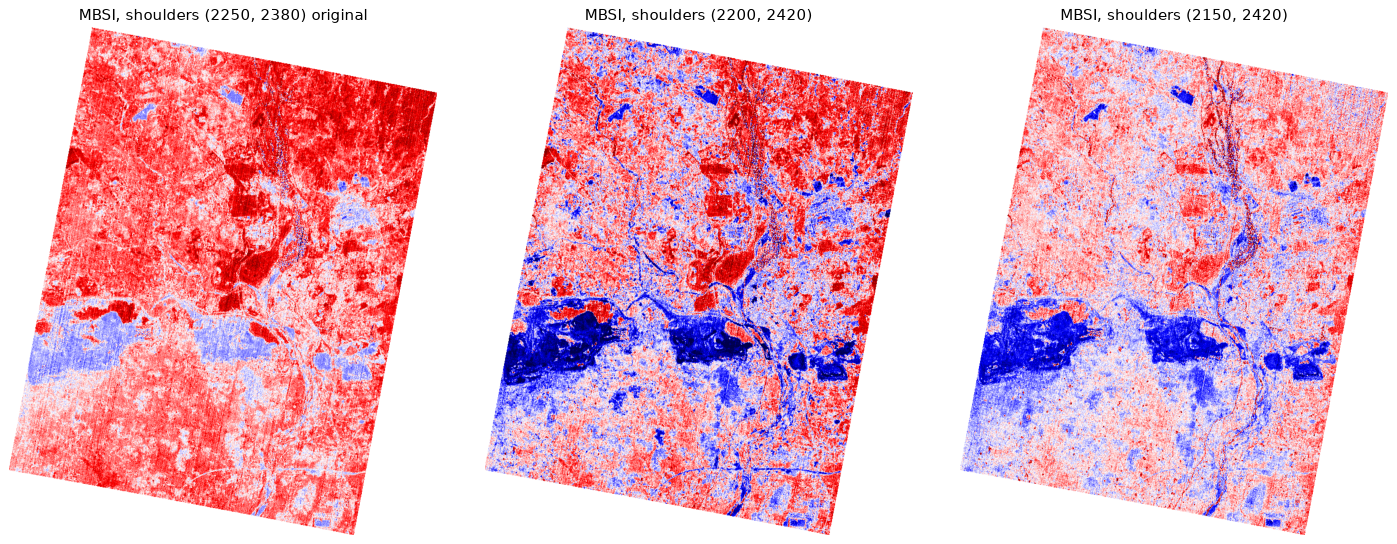

In [4]:
def top(x, q=99.5):
    return ok & (x > np.nanpercentile(x[ok], q))

versions = {"(2250, 2380) original": MBSI,
            "(2200, 2420)": mbsi(ref1=2200, ref2=2420),
            "(2150, 2420)": mbsi(ref1=2150, ref2=2420)}
A = top(MBSI)
for name, v in versions.items():
    B = top(v)
    print(f"{name:24s} r = {np.corrcoef(MBSI[ok], v[ok])[0, 1]:.2f}   Jaccard(top 0.5%) = {(A & B).sum() / (A | B).sum():.2f}")

fig, axes = plt.subplots(1, 3, figsize=(16, 6))
for ax, (name, v) in zip(axes, versions.items()):
    ax.imshow(np.where(ok, v, np.nan), cmap="seismic", vmin=-0.1, vmax=0.1); ax.set_title(f"MBSI, shoulders {name}"); ax.axis("off")
plt.tight_layout(); plt.show()

**Interpretation:** the maps look broadly similar (r ≈ 0.75–0.85), because they are all dominated by the same
land-surface pattern. But the **hot-spot sets barely overlap**: only about 8–15% of the top pixels are shared.
A real gas absorption would be found whichever reasonable shoulders you choose. An "anomaly" that moves when
you change the reference bands is noise or surface variability, not a detection.

## Exercise 3 — Surface-driven false positives  ⭐⭐

Test the suspicion that MBSI measures the surface type:

1. Make box plots of MBSI per WorldCover class (tree cover 10, grassland 30, cropland 40, built-up 50,
   bare / mines 60, water 80), using pure pixels only.
2. Compute the correlation of MBSI with NDVI and with albedo (`ALBEDO`).
3. Which surface type would a naive MBSI threshold flag most often? Which one least?

### Solution

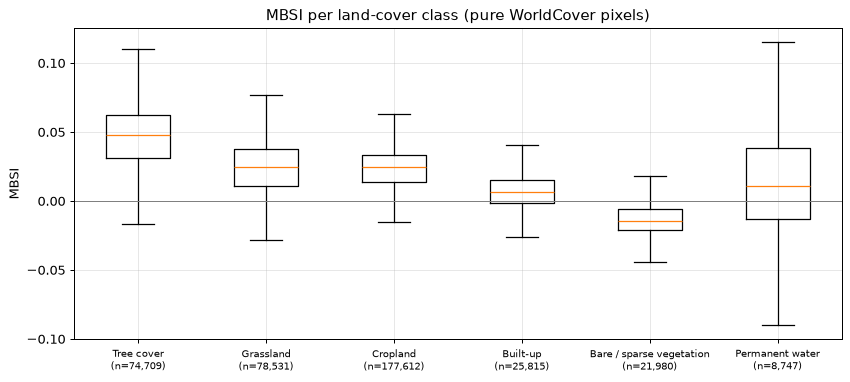

corr(MBSI, NDVI)   = +0.71
corr(MBSI, albedo) = +0.01


In [5]:
classes = [10, 30, 40, 50, 60, 80]
data = [MBSI[ok & (wc == c) & (purity == 9)] for c in classes]
names = [f"{hu.WORLDCOVER_CLASSES[c][0]}\n(n={d.size:,})" for c, d in zip(classes, data)]
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.boxplot(data, showfliers=False)
ax.set_xticks(range(1, len(classes) + 1), names, fontsize=8)
ax.axhline(0, color="grey", lw=0.8); ax.set_ylabel("MBSI"); ax.grid(alpha=0.3)
ax.set_title("MBSI per land-cover class (pure WorldCover pixels)")
plt.show()

print(f"corr(MBSI, NDVI)   = {np.corrcoef(MBSI[ok], NDVI[ok])[0, 1]:+.2f}")
print(f"corr(MBSI, albedo) = {np.corrcoef(MBSI[ok], ALBEDO[ok])[0, 1]:+.2f}")

**Interpretation:** MBSI is highest over **tree cover**, followed by crops and grassland, and lowest over
**bare ground and the mines**. It correlates strongly with NDVI (r ≈ 0.7) but hardly at all with albedo. A naive
MBSI threshold would therefore "detect methane" over forests — exactly the wrong places — while the coal mines,
a plausible real methane source, look clean. The index maps the **SWIR shape of the surface**, not the
atmosphere.

## Exercise 4 — Why do trees look like methane?  ⭐⭐⭐

Explain the false positives with spectra:

1. Plot the 2100–2450 nm part of the mean spectra of (a) the top-0.5% MBSI pixels, (b) pure bare/mine pixels
   (WorldCover 60) and (c) pure cropland, each **divided by its own value at 2250 nm**, so that only the shape
   remains. Mark the two shoulder and two absorption bands.
2. Compute MBSI on the course reference library spectra (`hu.load_library()`), which were measured in scenes
   where there is no reason to expect methane. Which materials give the highest MBSI?

### Solution

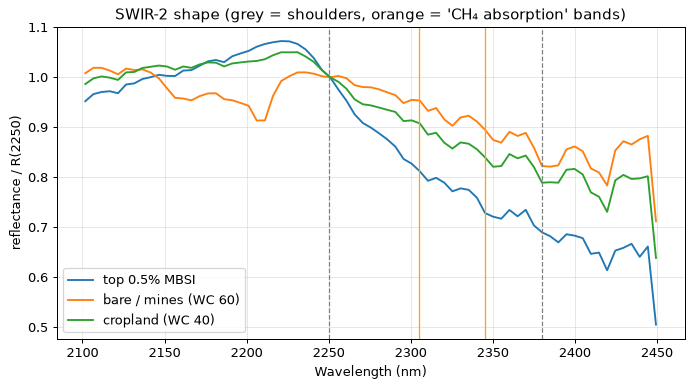

mangrove                 MBSI = +0.127
dry_steppe_grassland     MBSI = +0.121
tropical_tree_cover      MBSI = +0.109
sabkha_salt_flat         MBSI = +0.101
chaparral_unburned       MBSI = +0.096
sugarcane_cropland       MBSI = +0.083
irrigated_crop           MBSI = +0.047
desert_sand              MBSI = +0.038
burn_scar                MBSI = +0.018
dry_bare_soil            MBSI = +0.017
shallow_coastal_water    MBSI = -0.001
coal_mine_surface        MBSI = -0.008
sand_beach               MBSI = -0.010
mine_spoil_bright        MBSI = -0.019
turbid_estuary_water     MBSI = -0.020
bright_industrial_roof   MBSI = -0.026
river_water              MBSI = -0.027
dense_urban              MBSI = -0.028
clear_ocean              MBSI = -0.190


In [6]:
def mean_spec(mask, max_px=400):
    rows, cols = np.nonzero(mask)
    pick = np.random.default_rng(0).choice(len(rows), size=min(max_px, len(rows)), replace=False)
    rows, cols = rows[pick], cols[pick]
    cube, wl = scene.read_cube((rows.min(), rows.max() + 1, cols.min(), cols.max() + 1))
    return np.nanmean(cube[:, rows - rows.min(), cols - cols.min()], axis=1), wl

hot = ok & (MBSI > np.nanpercentile(MBSI[ok], 99.5))
groups = {"top 0.5% MBSI": hot, "bare / mines (WC 60)": ok & (wc == 60) & (purity == 9),
          "cropland (WC 40)": ok & (wc == 40) & (purity == 9)}
fig, ax = plt.subplots(figsize=(9, 4.5))
for name, m in groups.items():
    spec, wl = mean_spec(m)
    sel = (wl >= 2100) & (wl <= 2450)
    ax.plot(wl[sel], spec[sel] / spec[hu.band_index(wl, 2250)], label=name)
for w, style in ((2250, "--"), (2380, "--"), (2305, "-"), (2345, "-")):
    ax.axvline(w, color="orange" if style == "-" else "grey", ls=style, lw=1)
ax.set_xlabel("Wavelength (nm)"); ax.set_ylabel("reflectance / R(2250)"); ax.legend(); ax.grid(alpha=0.3)
ax.set_title("SWIR-2 shape (grey = shoulders, orange = 'CH₄ absorption' bands)")
plt.show()

wl_lib, lib, meta = hu.load_library()
b = {w: hu.band_index(wl_lib, w) for w in (2250, 2305, 2345, 2380)}
lib_mbsi = {k: (s[b[2250]] + s[b[2380]]) / (s[b[2305]] + s[b[2345]]) - 1 for k, s in lib.items()}
for k, v in sorted(lib_mbsi.items(), key=lambda kv: -kv[1]):
    print(f"{k:24s} MBSI = {v:+.3f}")

**Interpretation:** normalised at 2250 nm, the vegetated spectra **curve downwards** between 2250 and 2380 nm:
the "absorption" bands at 2305/2345 nm lie on a slope that is concave in the middle, shaped by leaf water,
cellulose and lignin. That curvature alone makes MBSI positive. Soils and mine surfaces are flatter or even
convex in this window, so their MBSI is low. The library confirms it: the vegetation spectra (mangrove,
chaparral, crops) give MBSI values comparable to the scene's "hot spots", even though they were measured in
scenes where nobody expects methane. Some bright minerals (carbonates absorb near 2340 nm) can do the same.

**Lesson:** a band ratio cannot separate a gas absorption from a surface absorption at the same wavelength. Real
methane retrievals (e.g. the matched filter of Thompson et al., 2015, and MAG1C by Foote et al., 2020) work on
**radiance**, model the gas's transmission spectrum at full spectral resolution, and statistically whiten the
scene background, so that the surface variability is suppressed.

## Exercise 5 — What does the GHG-plumes catalogue actually provide?  ⭐⭐

*Needs internet.* The STAC items in the `GHG-plumes` collection contain more than reflectance.

1. Fetch the STAC item of this scene (`hu.fetch_item(SCENE_ID, "GHG-plumes")`) and print its `notes`,
   `plume_provider_ids` and the list of asset keys.
2. The `ortho_ql_ch4` asset is a methane quick-look raster on the same grid as the reflectance, produced by the
   plume provider. Open it with `rasterio` and count the pixels flagged as methane.
3. Print the `notes` of all GHG-plumes items in the course catalogue index (`hu.load_catalog_index()`).
   Which scenes would you use to develop and test a methane detector?

### Solution

In [7]:
import rasterio

try:
    item = hu.fetch_item(SCENE_ID, "GHG-plumes")
    p = item["properties"]
    print("notes             :", p.get("notes"))
    print("plume_provider_ids:", p.get("plume_provider_ids"))
    print("assets            :", sorted(item["assets"]))
    with rasterio.open(item["assets"]["ortho_ql_ch4"]["href"]) as src:
        ql = src.read(1)
        print(f"ortho_ql_ch4: {ql.shape}, same grid as the SR cube: {ql.shape == scene.shape[1:]}, "
              f"provider: {src.tags().get('TIFFTAG_IMAGEDESCRIPTION')}, flagged pixels: {(ql > 0).sum()}")
    plumes = hu._get_json(item["assets"]["ql_ch4_json"]["href"])
    print("ql_ch4_json features:", len(plumes["features"]))
except Exception as err:
    print("Offline or catalogue unavailable:", err)

notes             : No methane plumes detected, but there is a CO2 plume present in this collect
plume_provider_ids: ['tan20250219t053246c00s4001-A', 'tan20250219t053246c00s4001-B', 'tan20250219t053246c00s4001-C', 'tan20250219t053246c00s4001-D', 'tan20250219t053246c00s4001-E', 'tan20250219t053246c00s4001-F']
assets            : ['basic_beta_udm', 'basic_radiance_hdf5', 'basic_sr_hdf5', 'geolocation_array', 'ortho_beta_udm', 'ortho_ql_ch4', 'ortho_radiance_hdf5', 'ortho_sr_hdf5', 'ortho_visual', 'ql_ch4_json', 'recent_monthly_mosaic', 'thumbnail']


ortho_ql_ch4: (961, 811), same grid as the SR cube: True, provider: {"plume_provider": "carbon_mapper"}, flagged pixels: 0


ql_ch4_json features: 0


In [8]:
index = hu.load_catalog_index()
ghg = index[index.collection == "GHG-plumes"][["id", "location"]].reset_index(drop=True)
notes = []
for sid in ghg["id"]:
    try:
        notes.append(hu.fetch_item(sid, "GHG-plumes")["properties"].get("notes"))
    except Exception:
        notes.append("(offline)")
ghg["notes"] = notes
ghg["location"] = ghg["location"].str.slice(0, 45)
with __import__("pandas").option_context("display.max_colwidth", 90):
    display(ghg)

,id,location,notes
0,20241004_081921_28_4001,"As-Sa'duni, Khasham Subdistrict, Deir ez-Zor",Plumes E and F represent the combined plume formed by merging sources that share a sin...
1,20241121_183741_33_4001,"Casa Grande, Pinal County, Arizona, United St",Controlled release plume example. Plume A is a conrolled release.
2,20250114_062056_92_4001,"Ghazi, Rojhan Tehsil, Rajanpur District, Dera",Potential NH3 plume detected in addition to CH4
3,20250219_053251_31_4001,"Kusmunda, Katghora Tahsil, Korba, Chhattisgar","No methane plumes detected, but there is a CO2 plume present in this collect"
4,20250226_065447_19_4001,"Purovsky Rayon, Yamalo-Nenets Autonomous Okru",Plumes E and F represent the combined plume formed by merging sources that share a sin...
5,20250423_134021_00_4001,Brazil Offshore,NaN
6,20250423_134026_31_4001,Brazil Offshore,NaN
7,20250703_063928_86_4001,"Kurgancha, Baliqchi District, Andijan Region,",Potential NH3 plume detected


**Interpretation:** the provider's notes for this scene say *"No methane plumes detected, but there is a CO₂
plume present in this collect"*. The methane quick-look (from Carbon Mapper) contains **zero** flagged pixels
and the plume GeoJSON is empty. So every MBSI "hot spot" you found in Exercise 1 is a **false positive**, and
the CO₂ plume (probably from a coal power plant stack) is invisible in the CH₄ window.

The GHG-plumes collection is therefore most valuable as a **test set with expert labels**: scenes with
confirmed plumes (e.g. oil and gas fields) give you true positives, and scenes like Korba give you realistic
true negatives over difficult surfaces. Always validate a detector on both.

## Exercise 6 — Reflection — from a band ratio to a defensible detection  ⭐

In a short markdown cell, describe the minimum workflow you would need before telling an environmental
regulator "there is a methane leak at this facility". Mention the input data level, the detection method, how
you would rule out surface false positives, and what independent evidence you would look for.

### Solution

**Model answer**
1. **Data:** start from **radiance** (`ortho_radiance_hdf5`), not reflectance. Atmospheric correction can
   partly remove or distort the gas absorption.
2. **Method:** a **matched filter** (or ACE / MAG1C) with a CH₄ unit-absorption spectrum computed with a
   radiative-transfer model for the scene geometry, applied per detector column with robust background
   statistics. The output is an enhancement in ppm·m, not a unitless index.
3. **False-positive control:** mask or model surfaces with SWIR-2 features (vegetation, carbonates,
   hydrocarbons such as plastics and asphalt). Require a spatially coherent plume that starts at a plausible
   source and is elongated along the **wind direction** (reanalysis wind data). Check that the signal does not
   depend on the choice of bands.
4. **Independent evidence:** known infrastructure (well pads, pipelines, landfills, mine vents), **repeat
   observations** that show the plume again (or the leak stopping), agreement with provider products (Carbon
   Mapper quick-looks) or other sensors (EMIT, PRISMA, EnMAP, GHGSat), and an uncertainty and emission-rate
   estimate (e.g. integrated mass enhancement with wind speed).

## Key takeaways

- A band ratio in the CH₄ window responds to surface SWIR shape (vegetation, minerals) as much as to gas.
- If a detection changes when you change arbitrary parameters, it is not a detection.
- Provider products and STAC notes are valuable reference data — use them to find true negatives, too.
- Real methane retrievals use radiance, a gas target spectrum and background statistics (matched filter).

---

> 📖 Data: Tanager — CC-BY-4.0 © Planet Labs PBC  
> 📖 Labels: ESA WorldCover 2021 v200 — CC-BY 4.0